# [GSE113915](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE113915)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-10-22
> - Modified: 2025-01-18

# 1. Experimental Design

> Uhrf1 regulates active transcriptional marks at bivalent domains in pluripotent stem cells through Setd1a.
> - Kim, KY., Tanaka, Y., Su, J. et al. Uhrf1 regulates active transcriptional marks at bivalent domains in pluripotent stem cells through Setd1a. Nat Commun 9, 2583 (2018). https://doi.org/10.1038/s41467-018-04818-0.
> - polyA RNA-seq
> - Illumina HiSeq 2000, SE100
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Status | Replicate |
| - | - | - | - | - | - | - | - |
| Uhrf1-WT | Mus musculus | mESC | Embryionic stem cell | E14 | Uhrf1-WT | Undifferentiated | None |
| Uhrf1-KO | Mus musculus | mESC | Embryionic stem cell | E14 | Uhrf1-KO | Undifferentiated | None |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Uhrf1_GSE113915/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)
head(raw_counts)

[1] 55335    16

,Geneid,Chr,Start,End,Strand,Length,gene_name,gene_type,mESC_Uhrf1_KO_Diff1W,mESC_Uhrf1_KO_Diff2W,mESC_Uhrf1_KO_Diff3W,mESC_Uhrf1_KO_Undiff,mESC_Uhrf1_WT_Diff1W,mESC_Uhrf1_WT_Diff2W,mESC_Uhrf1_WT_Diff3W,mESC_Uhrf1_WT_Undiff
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,ENSMUSG00000102693.1,chr1,3073253,3074322,+,1070,4933401J01Rik,TEC,0,0,0,0,0,0,0,0
2,ENSMUSG00000064842.1,chr1,3102016,3102125,+,110,Gm26206,snRNA,0,0,0,1,0,0,0,1
3,ENSMUSG00000051951.5,chr1;chr1;chr1;chr1;chr1;chr1;chr1,3205901;3206523;3213439;3213609;3214482;3421702;3670552,3207317;3207317;3215632;3216344;3216968;3421901;3671498,-;-;-;-;-;-;-,6094,Xkr4,protein_coding,8,31,57,27,53,62,125,43
4,ENSMUSG00000102851.1,chr1,3252757,3253236,+,480,Gm18956,processed_pseudogene,0,0,0,0,0,0,1,0
5,ENSMUSG00000103377.1,chr1,3365731,3368549,-,2819,Gm37180,TEC,0,0,0,0,0,0,2,2
6,ENSMUSG00000104017.1,chr1,3375556,3377788,-,2233,Gm37363,TEC,0,0,0,1,0,0,0,0


In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("Undiff"))) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status)) |> 
    arrange(Group, Status) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Status
,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
KO_Undiff,mESC,Uhrf1,KO,Undiff


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("Undiff")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

head(raw_counts)

,WT_Undiff,KO_Undiff
ENSMUSG00000102693.1,0,0
ENSMUSG00000064842.1,1,1
ENSMUSG00000051951.5,43,27
ENSMUSG00000102851.1,0,0
ENSMUSG00000103377.1,2,0
ENSMUSG00000104017.1,0,1


In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 55335 2 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(2): WT_Undiff KO_Undiff
colData names(4): Cell Gene Group Status

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE) |>
    str_subset(pattern = "Undiff")

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status)) |> 
    arrange(Group, Status) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Status") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Gene,Group,Status
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC_Uhrf1_WT_Undiff.tsv,mESC,Uhrf1,WT,Undiff
KO_Undiff,mESC_Uhrf1_KO_Undiff.tsv,mESC,Uhrf1,KO,Undiff


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 2 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(2): WT_Undiff KO_Undiff
colData names(4): Cell Gene Group Status

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Undiff")
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status)) |> 
    arrange(Group, Status) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Status
,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
KO_Undiff,mESC,Uhrf1,KO,Undiff


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 2 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(2): WT_Undiff KO_Undiff
colData names(4): Cell Gene Group Status

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Undiff")

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        names = sub("^[^_]+_[^_]+_", "", names),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status)) |> 
    arrange(Group, Status) |>
    select("names", "files", "Cell", "Gene", "Group", "Status") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files"))

names,Cell,Gene,Group,Status
<chr>,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
KO_Undiff,mESC,Uhrf1,KO,Undiff


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-11 03:19:45

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene mapping from database

generating

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 2 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(2): WT_Undiff KO_Undiff
colData names(5): names Cell Gene Group Status

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Undiff")
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status)) |> 
    arrange(Group, Status) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Status
,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
KO_Undiff,mESC,Uhrf1,KO,Undiff


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 2 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(2): WT_Undiff KO_Undiff
colData names(4): Cell Gene Group Status

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 2 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(2): WT_Undiff KO_Undiff
colData names(4): Cell Gene Group Status

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 2 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(2): WT_Undiff KO_Undiff
colData names(4): Cell Gene Group Status

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

lapply(dgel, head)

$counts
                     WT_Undiff KO_Undiff
ENSMUSG00000102693.1         0         0
ENSMUSG00000064842.1         1         1
ENSMUSG00000051951.5        43        27
ENSMUSG00000102851.1         0         0
ENSMUSG00000103377.1         2         0
ENSMUSG00000104017.1         0         1

$samples
          group  lib.size norm.factors Cell  Gene Group Status
WT_Undiff    WT 164985675            1 mESC Uhrf1    WT Undiff
KO_Undiff    KO 170104179            1 mESC Uhrf1    KO Undiff

$genes
                            symbol                 type basepairs
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
ENSMUSG00000104017.1       Gm37363                  TEC      2233

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 1
# keep <- rowSums(counts(dds) >= 10) >= 1

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 24313 
 Remove: 31022 
 Retention rate: 43.94 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 23916 
 Remove: 31419 
 Retention rate: 43.22 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,0.26068819,0.15875032
ENSMUSG00000102948.1,0.07881271,0.04703713
ENSMUSG00000025902.13,1.04275275,2.69287577
ENSMUSG00000102269.1,0.77600205,0.54092701
ENSMUSG00000102735.1,0.07881271,0.02939821
ENSMUSG00000098104.1,1.08519037,0.74671446


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,0.04277785,0.02605027
ENSMUSG00000102948.1,0.04221356,0.02519396
ENSMUSG00000025902.13,0.21851483,0.56430758
ENSMUSG00000102269.1,0.25944569,0.18085156
ENSMUSG00000102735.1,0.08420161,0.03140834
ENSMUSG00000098104.1,0.73822474,0.50796902


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,0.1495920,0.08662458
ENSMUSG00000102948.1,0.1476187,0.08377714
ENSMUSG00000025902.13,0.7641353,1.87648412
ENSMUSG00000102269.1,0.9072684,0.60138316
ENSMUSG00000102735.1,0.2944488,0.10444172
ENSMUSG00000098104.1,2.5815345,1.68914229


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,42.15473,27.541394
ENSMUSG00000102948.1,12.74445,8.160413
ENSMUSG00000025902.13,168.61892,467.183649
ENSMUSG00000102269.1,125.48384,93.844750
ENSMUSG00000102735.1,12.74445,5.100258
ENSMUSG00000098104.1,175.48131,129.546558


,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,0.04129959,0.02698270
ENSMUSG00000102948.1,0.04075480,0.02609574
ENSMUSG00000025902.13,0.21096370,0.58450613
ENSMUSG00000102269.1,0.25048012,0.18732487
ENSMUSG00000102735.1,0.08129189,0.03253256
ENSMUSG00000098104.1,0.71271420,0.52615101


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,0.25233613,0.16401018
ENSMUSG00000102948.1,0.07628767,0.04859561
ENSMUSG00000025902.13,1.00934451,2.78209869
ENSMUSG00000102269.1,0.75114010,0.55884952
ENSMUSG00000102735.1,0.07628767,0.03037226
ENSMUSG00000098104.1,1.05042248,0.77145531


,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,0.04140731,0.02691339
ENSMUSG00000102948.1,0.04086110,0.02602871
ENSMUSG00000025902.13,0.21151394,0.58300475
ENSMUSG00000102269.1,0.25113343,0.18684370
ENSMUSG00000102735.1,0.08150392,0.03244899
ENSMUSG00000098104.1,0.71457312,0.52479953


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

Warning message in voom(dgel, design, plot = FALSE):
"The experimental design has no replication. Setting weights to 1."


,WT_Undiff,KO_Undiff
ENSMUSG00000051951.5,-1.96990259,-2.5816705
ENSMUSG00000102948.1,-3.65795858,-4.2755674
ENSMUSG00000025902.13,0.01760647,1.4777477
ENSMUSG00000102269.1,-0.40722153,-0.8316487
ENSMUSG00000102735.1,-3.65795858,-4.9035986
ENSMUSG00000098104.1,0.07499395,-0.3686768


## Summary

In [36]:
suppressPackageStartupMessages(library(vsn))

In [37]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [38]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


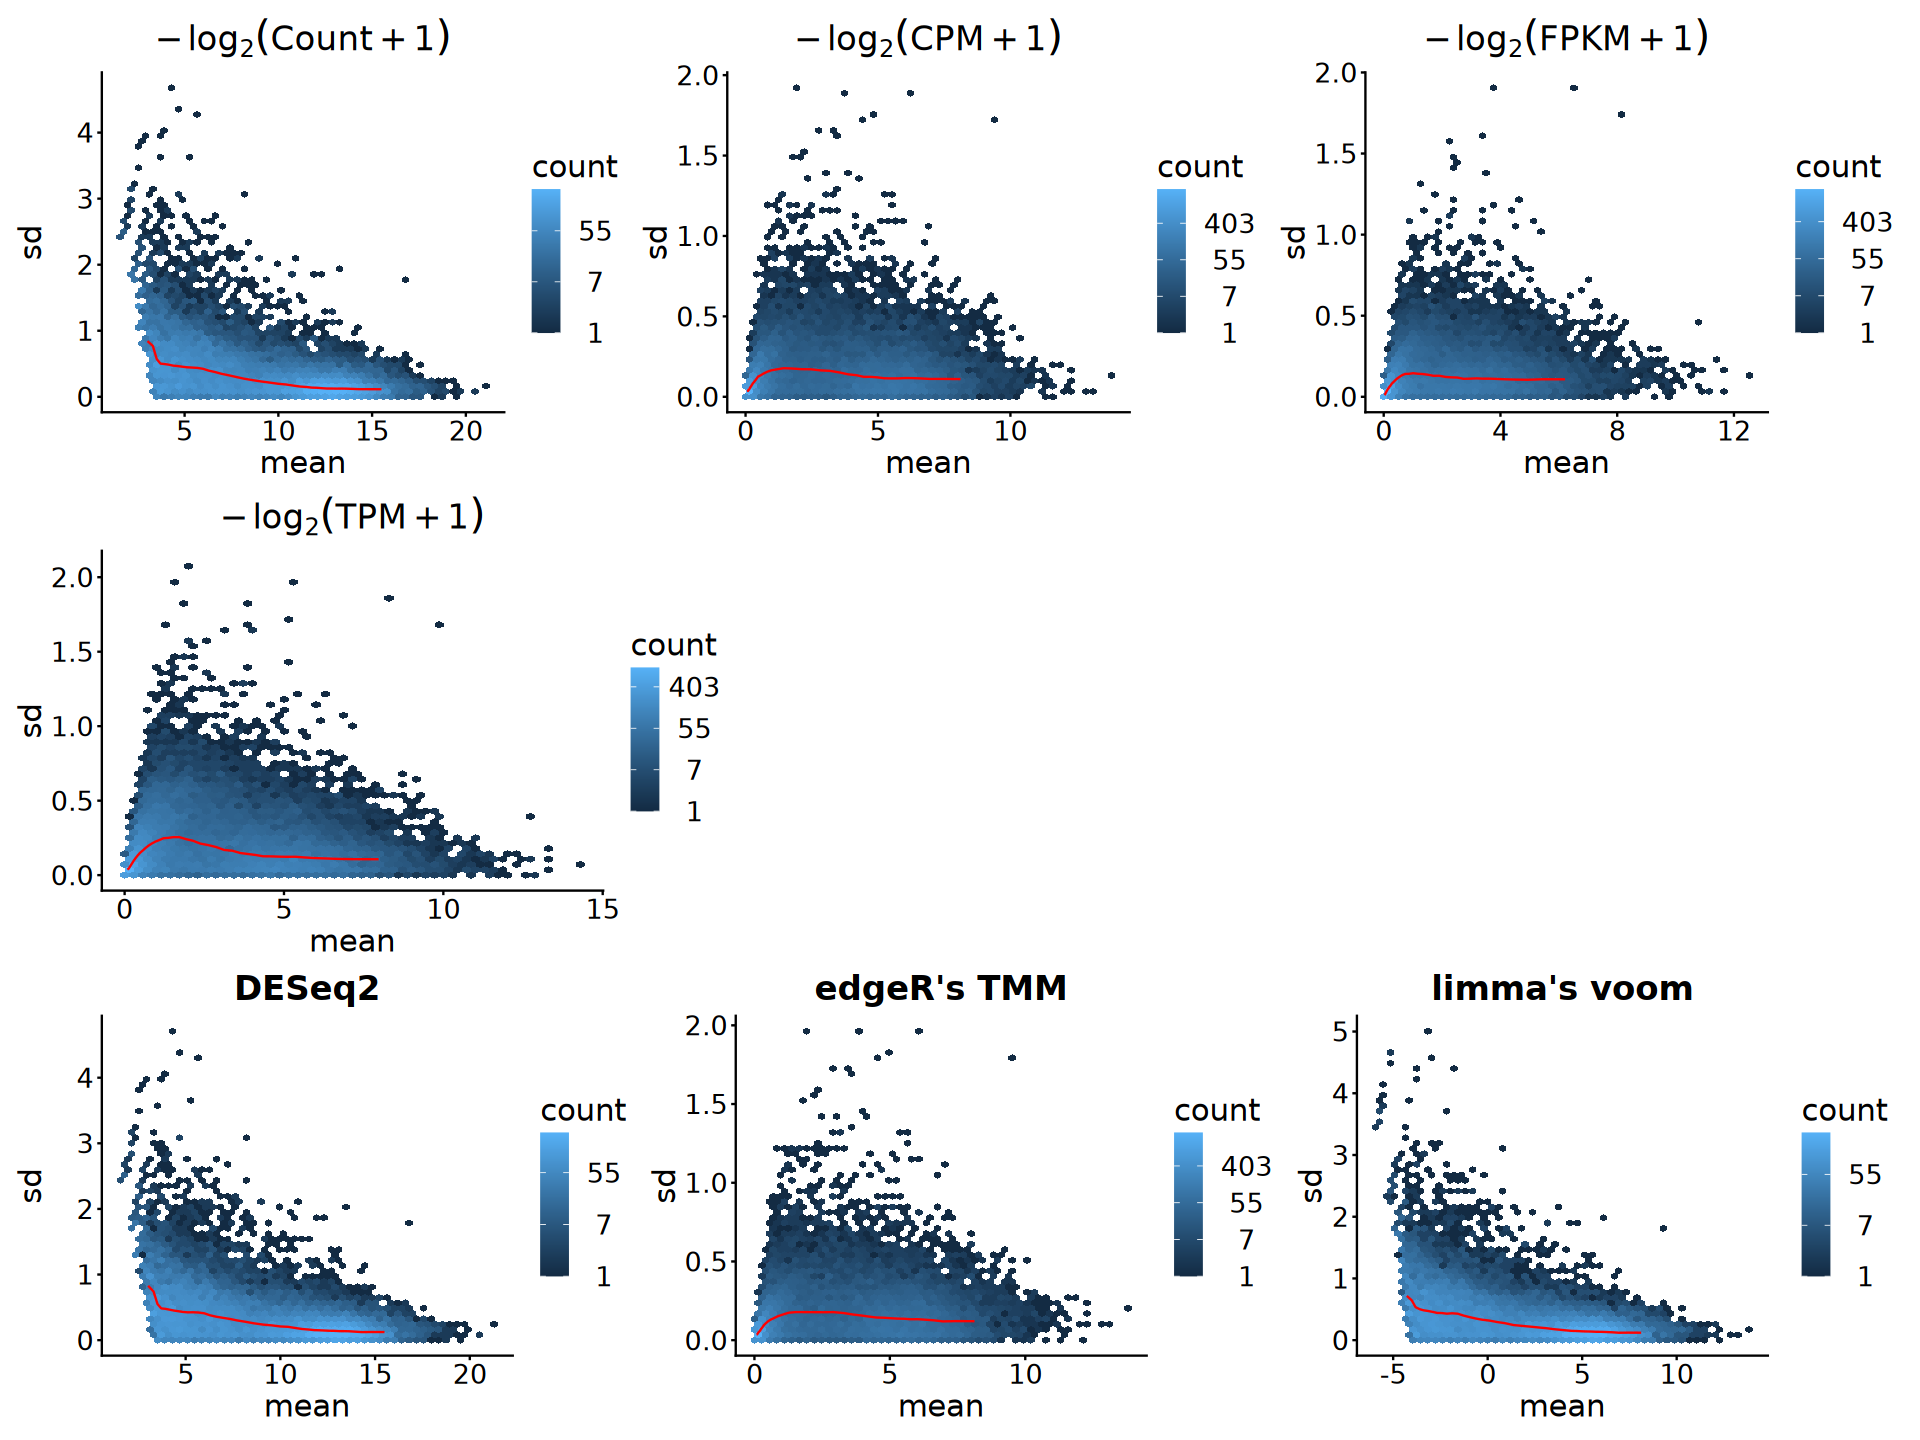

In [39]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + plot_spacer() + plot_spacer()) / (p7 + p8 + p9)

# 4. Exploration

In [40]:
norm_mat <- log2(tpm + 1)

### 1). Overview

In [41]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Status) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

plot_df

Sample,Cell,Gene,Group,Status,librarySize
<fct>,<chr>,<chr>,<fct>,<fct>,<dbl>
WT Undiff,mESC,Uhrf1,WT,Undiff,164948018
KO Undiff,mESC,Uhrf1,KO,Undiff,170078399


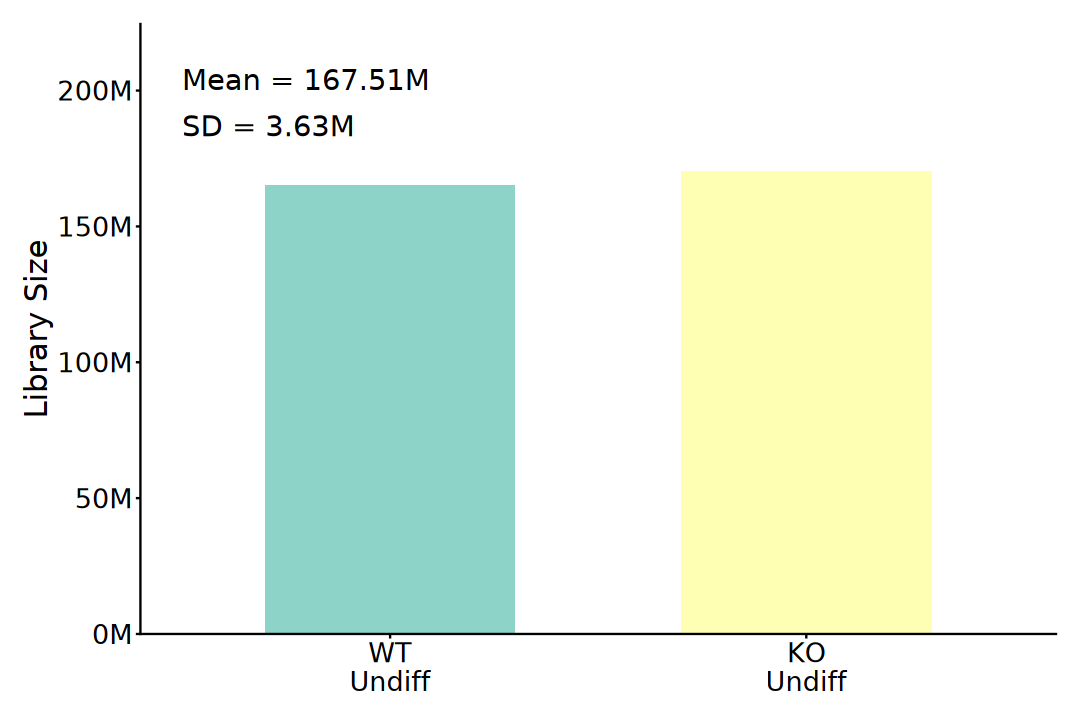

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_col(aes(fill = Sample), width = 0.6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.2,
        label = paste0("Mean = ", round(
            mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("SD = ", round(
            sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [43]:
# remotes::install_github("psyteachr/introdataviz")
suppressPackageStartupMessages(library(introdataviz))

Warning message:
"Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead."


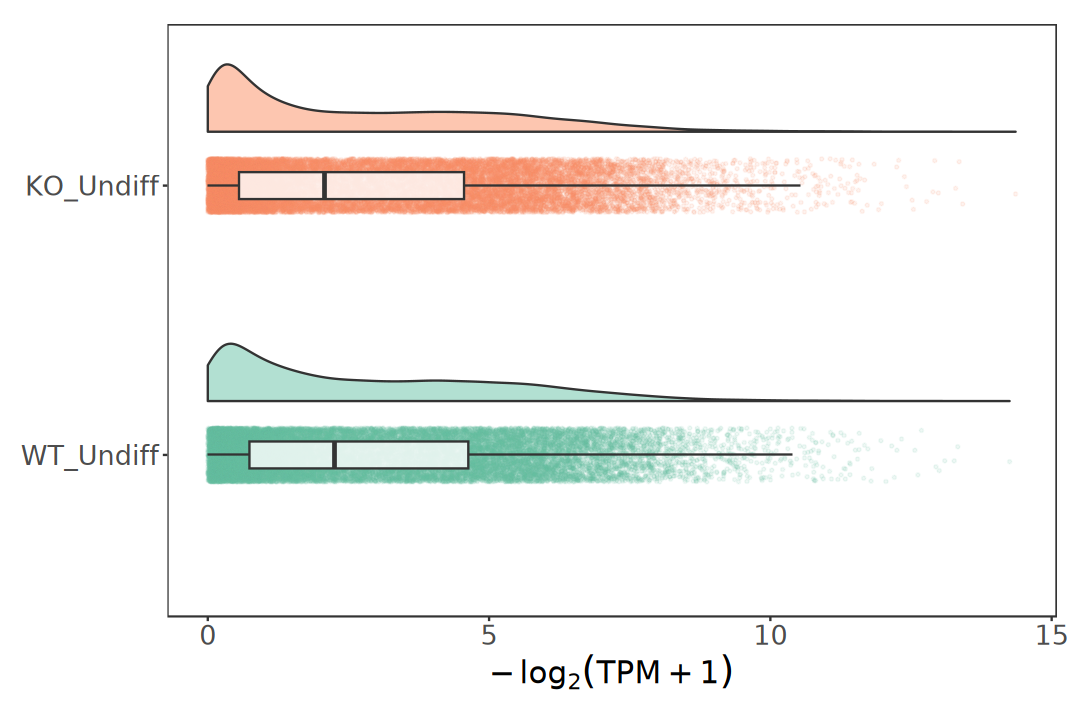

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_mat |> as.data.frame() |> 
    pivot_longer(
        cols = everything(), names_to = "Sample", 
        values_to = "Value") |>
    mutate(
        Sample = factor(Sample, levels = colnames(norm_mat))) |>
    ggplot(aes(x = Sample, y = Value)) +
        geom_flat_violin(
            aes(fill = Sample), width = 0.5, alpha = 0.5,
            position = position_nudge(x = 0.2, y = 0)) +
        geom_point(
            aes(color = Sample), size = 0.5, alpha = 0.1,
            position = position_jitter(width = 0.1)) + 
        geom_boxplot(
            width = 0.1, alpha = 0.8, outlier.shape = NA) +
        scale_fill_brewer(palette = "Set2") +
        scale_colour_brewer(palette = "Set2") +
        coord_flip() +
        labs(x = NULL, y = expression(-log[2](TPM+1))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.position = "none",
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

In [45]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [46]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Status, Group)

In [47]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
status_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Status)),
    levels(eSet$Status))

anno_colors <- list(
    Group = group_colors,
    Status = status_colors)

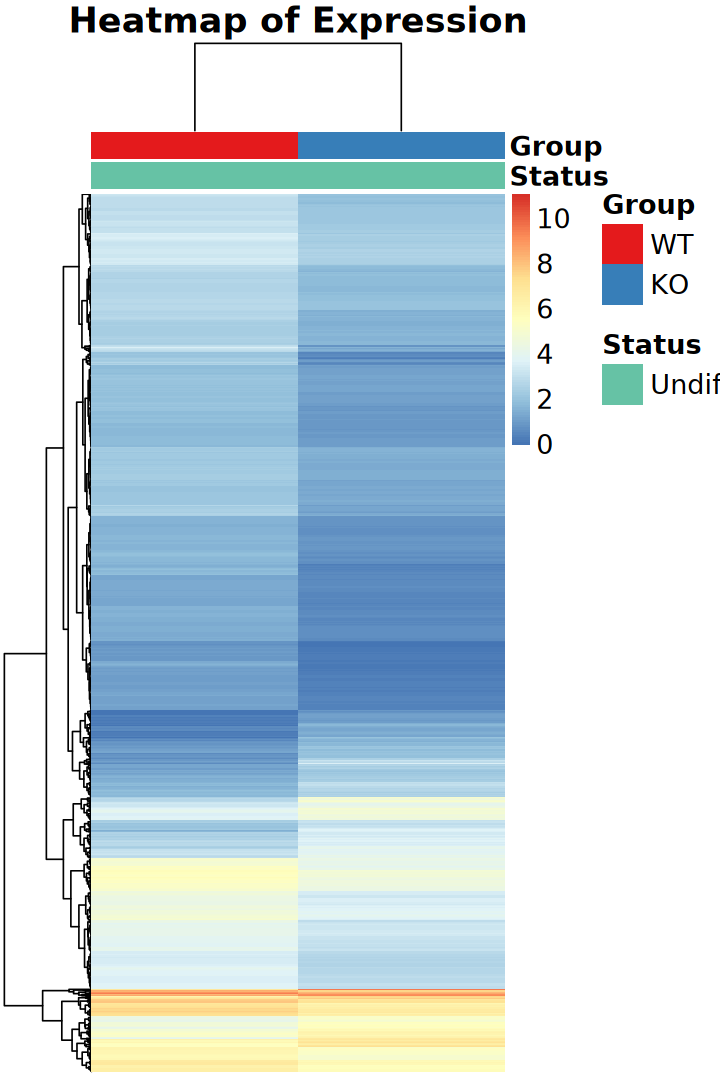

In [48]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [49]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## 1). edgeR

### a). BCV

> Biological coefficient of variation (BCV)

In [50]:
bcv <- 0.1

In [51]:
design <- model.matrix(~ group, data = dgel$samples)
design

,(Intercept),groupKO
WT_Undiff,1,0
KO_Undiff,1,1


In [52]:
# exact test
# et <- exactTest(dgel, dispersion = bcv^2)
# likelihood ratio test
fit <- glmFit(dgel, design, dispersion = bcv^2)
lrt <- glmLRT(fit, coef = 2)

In [53]:
edger_bcv_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_bcv_result$result)
head(edger_bcv_result)


   Up  Down    NS 
  842  1438 21636 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022123.9,Scel,protein_coding,2503,4.435315,2.1379009,268.4134,2.515963e-60,6.017177e-56,Up
ENSMUSG00000064039.4,Ccr1l1,protein_coding,1166,6.295738,0.2705601,227.7736,1.823471e-51,2.180507e-47,Up
ENSMUSG00000006200.3,Rhox6,protein_coding,1010,3.020182,4.3015038,179.1526,7.420783e-41,5.915848e-37,Up
ENSMUSG00000031871.9,Cdh5,protein_coding,4203,3.400639,1.7390299,175.8762,3.853678e-40,2.304114e-36,Up
ENSMUSG00000055298.6,Ctsj,protein_coding,1425,6.729886,-0.5601611,169.1869,1.113697e-38,5.327036e-35,Up
ENSMUSG00000069044.6,Usp9y,protein_coding,8094,3.754418,0.7430464,164.3422,1.273550e-37,4.693625e-34,Up


### b). Reduced

In [54]:
design_reduced <- model.matrix(~ 1, data = dgel$samples)
design_reduced

design_full <- model.matrix(~ group, data = dgel$samples)
design_full

,(Intercept)
WT_Undiff,1
KO_Undiff,1


,(Intercept),groupKO
WT_Undiff,1,0
KO_Undiff,1,1


In [55]:
dgel_reduced <- estimateGLMCommonDisp(
    dgel, design = design_reduced, method = "deviance", 
    robust = TRUE, subset = NULL)

common_disp <- dgel_reduced$common.dispersion
cat("Estimated common dispersion:", common_disp) |> message()

Estimated common dispersion: 0.06149492

In [56]:
# likelihood ratio test
fit <- glmFit(dgel_reduced, design_full)
lrt <- glmLRT(fit, coef = 2)

In [57]:
edger_reduced_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_reduced_result$result)
head(edger_reduced_result)


   Up  Down    NS 
  205   115 23596 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000064039.4,Ccr1l1,protein_coding,1166,6.295738,0.2709359,71.28261,3.095526e-17,7.403261e-13,Up
ENSMUSG00000005891.7,Prl4a1,protein_coding,876,7.455483,-0.7524793,65.08575,7.170880e-16,8.574938e-12,Up
ENSMUSG00000055298.6,Ctsj,protein_coding,1425,6.729886,-0.5595702,64.19731,1.125623e-15,8.973464e-12,Up
ENSMUSG00000022123.9,Scel,protein_coding,2503,4.435315,2.1380104,54.69281,1.409212e-13,6.951551e-10,Up
ENSMUSG00000021348.3,Prl7d1,protein_coding,3785,5.342227,-0.4014782,54.63223,1.453327e-13,6.951551e-10,Up
ENSMUSG00000057170.6,Prl3d1,protein_coding,875,6.606718,-1.5752571,48.86358,2.743992e-12,1.093755e-08,Up


### c). Housekeeping

In [58]:
suppressPackageStartupMessages(library(org.Mm.eg.db))

In [59]:
HOUSEKEEPING_GENES <- readLines(
    "~/reference/Database/Housekeeping_Genes/HOUNKPE_HOUSEKEEPING_GENES.v2026.1.Mm.gmt", 
    warn = FALSE) |> 
    str_split("\t") |>
    (\(x) x[[1]])() |>
    (\(x) x[-c(1,2)])() |>
    unique()

In [60]:
gene_map <- clusterProfiler::bitr(
        HOUSEKEEPING_GENES, OrgDb = org.Mm.eg.db, drop = FALSE, 
        fromType = "SYMBOL", toType = "ENSEMBL")



'select()' returned 1:1 mapping between keys and columns



In [61]:
dgel_1 <- dgel
dgel_1$samples$group <- 1
dgel_1 <- dgel_1[sub("\\.[0-9]+$", "", rownames(dgel_1)) %in% gene_map$ENSEMBL, ]

dgel_0 <- estimateDisp(dgel_1, trend = "none", tagwise = FALSE)

common_disp <- dgel_0$common.dispersion
cat("Estimated common dispersion:", common_disp) |> message()

Using classic mode.



Estimated common dispersion: 0.01645021

In [62]:
design <- model.matrix(~ group, data = dgel$samples)
design

,(Intercept),groupKO
WT_Undiff,1,0
KO_Undiff,1,1


In [63]:
dgel_housekeeping <- dgel
dgel_housekeeping$common.dispersion <- common_disp
# likelihood ratio test
fit <- glmFit(dgel_housekeeping, design)
lrt <- glmLRT(fit, coef = 2)

In [64]:
edger_housekeeping_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_housekeeping_result$result)
head(edger_housekeeping_result)


   Up  Down    NS 
  776  1161 21979 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022123.9,Scel,protein_coding,2503,4.435315,2.1367715,179.4501,6.389938e-41,1.528218e-36,Up
ENSMUSG00000064039.4,Ccr1l1,protein_coding,1166,6.295738,0.2671436,174.6904,6.995422e-40,8.365126e-36,Up
ENSMUSG00000055298.6,Ctsj,protein_coding,1425,6.729886,-0.5649806,137.3018,1.035808e-31,8.257459e-28,Up
ENSMUSG00000005891.7,Prl4a1,protein_coding,876,7.455483,-0.7582991,132.7496,1.025664e-30,6.132447e-27,Up
ENSMUSG00000021348.3,Prl7d1,protein_coding,3785,5.342227,-0.4064277,126.1651,2.829425e-29,1.353371e-25,Up
ENSMUSG00000031871.9,Cdh5,protein_coding,4203,3.400639,1.7377228,117.4833,2.249883e-27,8.968034e-24,Up


### Evaluate DEGs

In [65]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [66]:
genes_up <- list(
    BCV = edger_bcv_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    Reduced = edger_reduced_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    HK = edger_housekeeping_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    BCV = edger_bcv_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    Reduced = edger_reduced_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    HK = edger_housekeeping_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [67]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

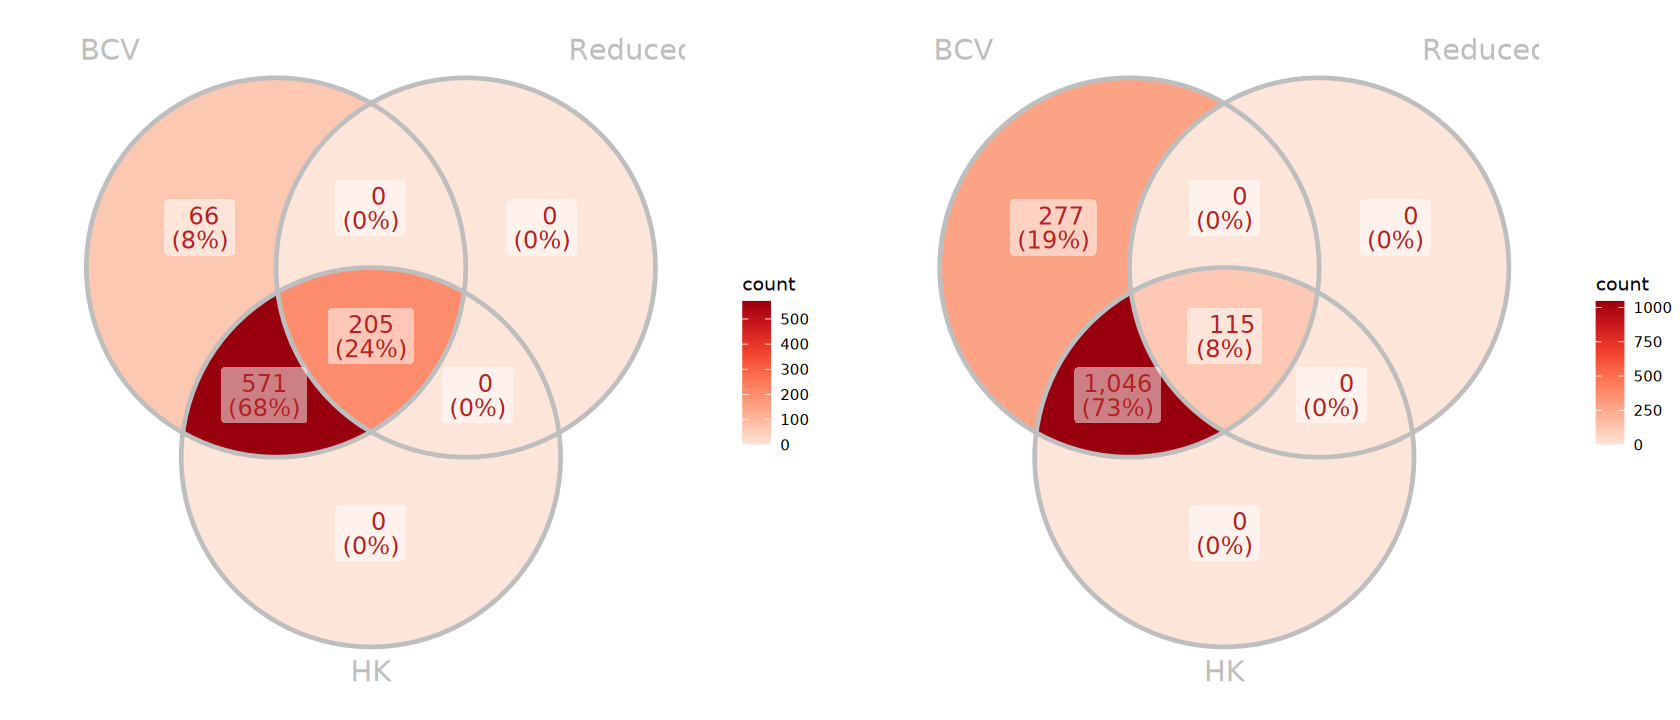

In [68]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). NOISeq

In [69]:
# BiocManager::install("NOISeq")
suppressPackageStartupMessages(library(NOISeq))

In [70]:
myCounts <- readData(
    data = assay(eSet), factors = colData(eSet), 
    length = rowData(eSet)$basepairs, 
    biotype = rowData(eSet)$type)
myCounts

ExpressionSet (storageMode: lockedEnvironment)
assayData: 24313 features, 2 samples 
  element names: exprs 
protocolData: none
phenoData
  sampleNames: WT_Undiff KO_Undiff
  varLabels: Cell Gene Group Status
  varMetadata: labelDescription
featureData
  featureNames: ENSMUSG00000051951.5 ENSMUSG00000102948.1 ...
    ENSMUSG00000064372.1 (24313 total)
  fvarLabels: Length Biotype
  fvarMetadata: labelDescription
experimentData: use 'experimentData(object)'
Annotation:  

In [71]:
noiseq_obj <- noiseq(
    myCounts, factor = "Group", k = NULL, norm = "n", pnr = 0.2, 
    nss = 5, v = 0.02, lc = 1, replicates = "no")

[1] "Computing (M,D) values..."
[1] "Computing probability of differential expression..."


In [72]:
head(noiseq_obj@results[[1]])

,WT_mean,KO_mean,M,D,prob,ranking,Length,Biotype
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
ENSMUSG00000051951.5,43,27,0.6713773,16,0.4170238,16.014080,NA,NA
ENSMUSG00000102948.1,13,8,0.7004397,5,0.2909164,5.048823,NA,NA
ENSMUSG00000025902.13,172,458,-1.4129390,286,0.8665549,-286.003490,NA,NA
ENSMUSG00000102269.1,128,92,0.4764380,36,0.4570271,36.003153,NA,NA
ENSMUSG00000102735.1,13,5,1.3785116,8,0.4421853,8.117900,NA,NA
ENSMUSG00000098104.1,179,127,0.4951311,52,0.5119627,52.002357,NA,NA


In [73]:
noiseq_up <- degenes(noiseq_obj, q = 0.9, M = "up")
noiseq_down <- degenes(noiseq_obj, q = 0.9, M = "down")

[1] "66 differentially expressed features (up in first condition)"
[1] "180 differentially expressed features (down in first condition)"


## 3). DEGseq

In [74]:
# BiocManager::install("DEGseq")
suppressPackageStartupMessages(library(DEGseq))

In [75]:
expr_ctrl_mat <- assay(eSet[, eSet$Group == "WT"]) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id")

In [76]:
expr_treat_mat <- assay(eSet[, eSet$Group == "KO"]) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id")

In [77]:
# DEGexp(
#     geneExpMatrix1 = expr_treat_mat, geneCol1 = 1, 
#     expCol1 = 2:ncol(expr_treat_mat), groupLabel1 = "KO",
#     geneExpMatrix2 = expr_ctrl_mat, geneCol2 = 1, 
#     expCol2 = 2:ncol(expr_ctrl_mat), groupLabel2 = "WT",
#     method = 'LRT', outputDir = "DEGexp_output")

## 4). DESeq

In [78]:
# BiocManager::install("DESeq")
# suppressPackageStartupMessages(library(DESeq))